In [42]:

import numpy as np
from collections import Counter

class node():
    def __init__(self, feature=None, threshold=None, left=None, right=None,*,value=None):
        self.feature = feature
        self.threshold =threshold
        self.left = left
        self.right = right
        self.value = value

    #to check if the node is a leaf or not
    def is_leaf_node(self):
        return self.value is not None


class decision_tree():

    def __init__(self, min_samples_split=2, max_depth=100, n_features=None):
        #stopping criteria
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_features = n_features #you get it from who defines the tree first, but we are initializing to add randomness
        self.root = None


    def fit(self, X, y):
        self.n_features = X.shape[1] if not self.n_features else min(X.shape[1], self.n_features)
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0): #checks the feature
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        #check stopping criteria
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return node(value=leaf_value)

        feat_idxs = np.random.choice(n_feats, self.n_features, replace=False)

        #if we don't stop here then:
        #find the best split
        best_feature, best_threshold = self._best_split(X, y, feat_idxs)

        #create child nodes
        left_idxs, right_idxs = self._split(X[:, best_feature],best_threshold)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth+1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth+1)
        return node(best_feature, best_threshold, left, right)

        #call function again on childnodes (recursion)

    def _best_split(self, X, y, feat_idxs): #what left and right trees are
        #finds threshold among all possible treshholds and splits
        best_gain = -1 #keep the first value
        split_idx, split_threshold = None, None

        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx] #get the column with only indexes
            thresholds =  np.unique(X_column) #get all possible tresholds

            for threshold in thresholds:
                #calculate the information gain
                gain = self._information_gain(y, X_column, threshold)

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_threshold = threshold
        return split_idx, split_threshold


    def _information_gain(self, y, X_column, threshold):
        #I_gain = E(parent)-[weighted average]*E(children)

        #parent enthropy
        parent_entropy = self._entropy(y)

        #children entropy
        left_idxs, right_idxs = self._split(X_column, threshold)

        #check if it is empty or not:
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0 #information gain is 0 if the branches are empty

        #weighted avg entropy of children
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = self._entropy(y[left_idxs]), self._entropy(y[right_idxs])
        child_entropy = (n_l/n)*e_l + (n_r/n)*e_r #use formulas
        #information gain
        information_gain = parent_entropy - child_entropy
        return information_gain

    def _split(self, X_column, split_threshold):
        #np.argwhere -> gives you the positions where your conditions meet in a list
        left_idxs = np.argwhere(X_column <= split_threshold).flatten()
        right_idxs = np.argwhere(X_column > split_threshold).flatten()
        return left_idxs, right_idxs

    def _entropy(self, y):
        #formla given: E = -sum(p(X))*log2(p(x));   p(X)= #x/n
        hist = np.bincount(y) #counts the times 0, 1, 2, etc has appeared
        ps = hist/len(y)
        return -np.sum([p * np.log(p) for p in ps if p>0]) #this is our entropy

    def _most_common_label(self, y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common

    def predict(self, X):
        return np.array([self._traverse_tree (x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf_node(): #check if it is leaf node
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)

        return self._traverse_tree(x, node.right)




In [51]:
#################################################################################

from sklearn import datasets
from sklearn.model_selection import train_test_split
import  numpy as np
#from decision_tree import decision_tree #if in other document

data = datasets.load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

clf = decision_tree(max_depth=50)
clf.fit(X_train, y_train)
predictions=clf.predict(X_test)

def accuracy(y_test, y_pred):
    accuracy = np.sum(y_test == y_pred)/len(y_test)
    return accuracy

acc=accuracy(y_test, predictions)
print(acc)

0.9122807017543859


In [55]:
def print_tree(node, feature_names, depth=0):
    """Recursively prints the tree with feature names."""
    indent = "  " * depth

    if node.is_leaf_node():
        print(f"{indent}Leaf: {node.value}")
    else:
        feature_name = feature_names[node.feature]
        print(f"{indent}{feature_name} <= {node.threshold}")
        print_tree(node.left, feature_names, depth + 1)
        print_tree(node.right, feature_names, depth + 1)
feature_names = data.feature_names  # Extract feature names from the dataset
print_tree(clf.root, feature_names)


mean concave points <= 0.05102
  worst radius <= 16.77
    area error <= 34.37
      worst texture <= 33.17
        Leaf: 1
        worst texture <= 33.37
          Leaf: 0
          Leaf: 1
      texture error <= 1.798
        Leaf: 1
        mean smoothness <= 0.08138
          Leaf: 1
          Leaf: 0
    mean texture <= 19.46
      mean concavity <= 0.05892
        Leaf: 1
        Leaf: 0
      Leaf: 0
  worst area <= 861.5
    worst texture <= 25.47
      worst concave points <= 0.1708
        mean concave points <= 0.05246
          Leaf: 0
          Leaf: 1
        Leaf: 0
      worst symmetry <= 0.2666
        Leaf: 1
        Leaf: 0
    Leaf: 0


#Theory

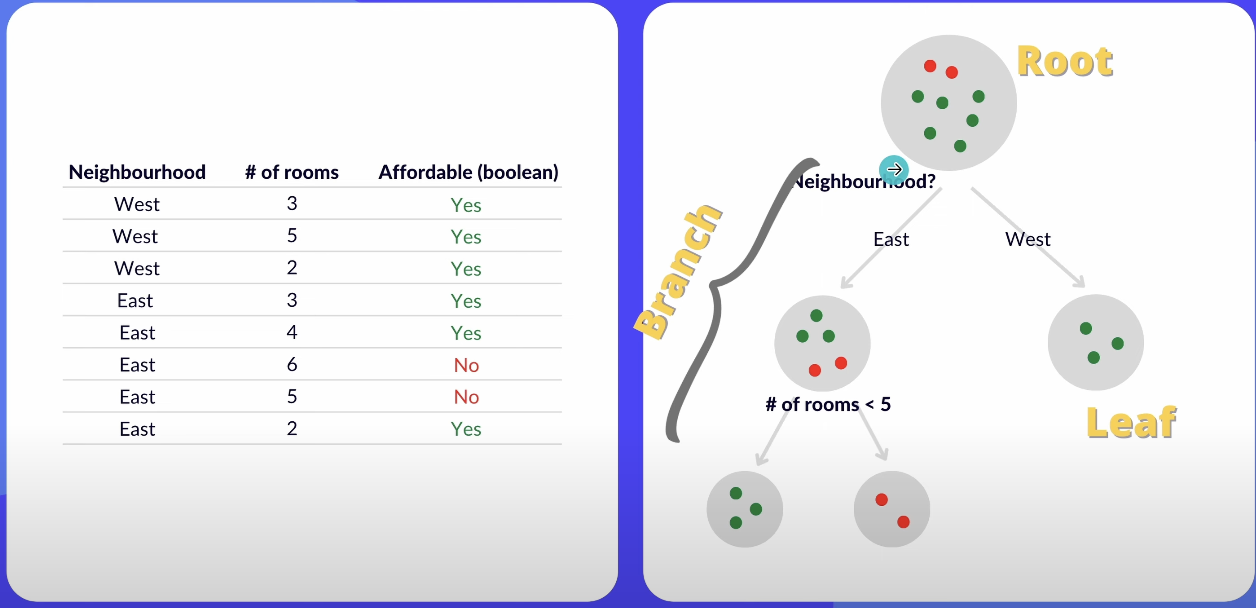

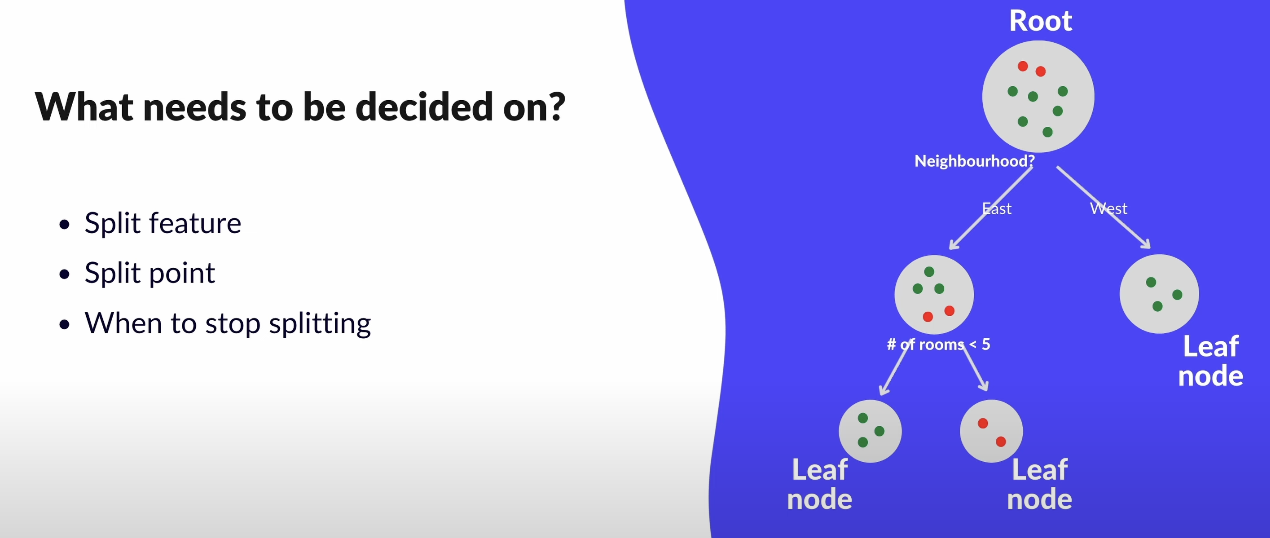

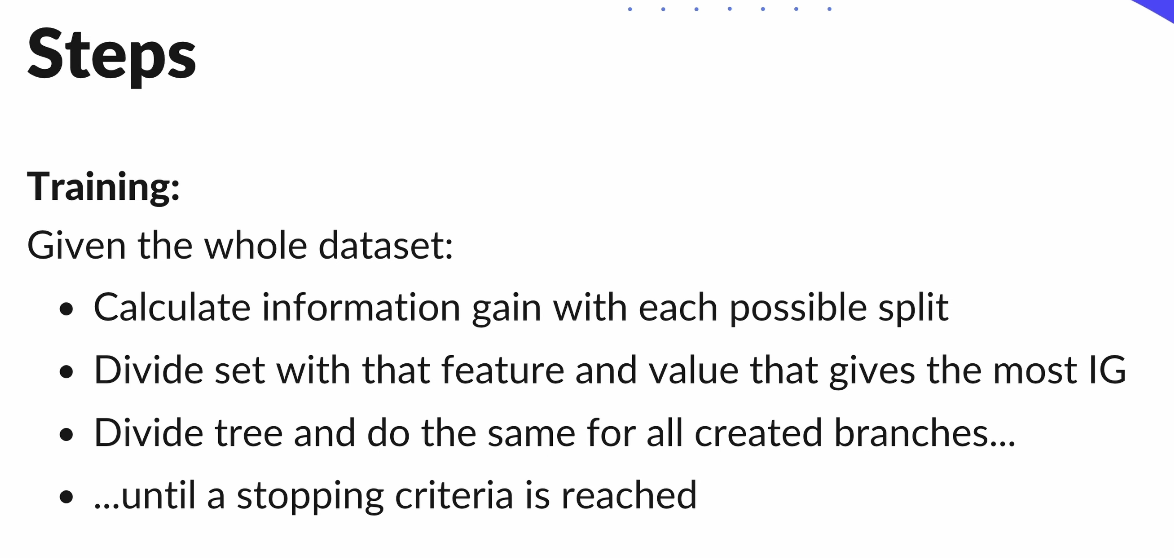

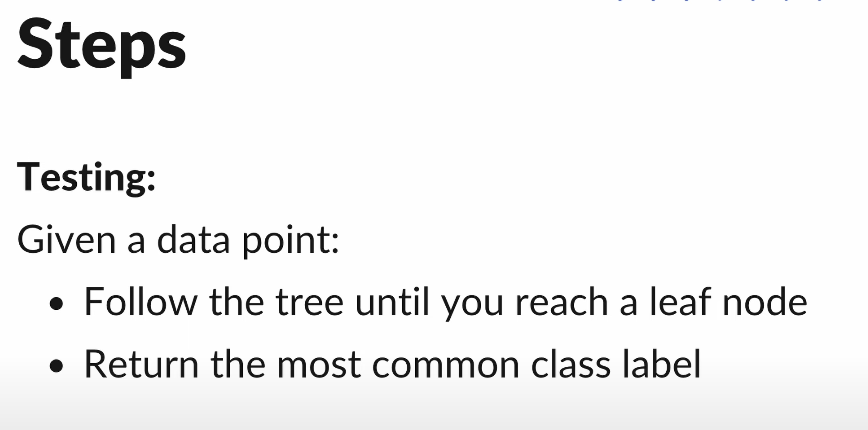